<a href="https://colab.research.google.com/github/Erick88santos/Dataset_shark_anotation/blob/main/DRONESHARK_4FOLD_AGRUPADO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DroneShark — Detecção binária de tubarões: validação cruzada 4-Fold (agrupada)

**O que este notebook faz**
1. Carrega o `dataset_shark_binario` (875 imagens: 731 com tubarão, 144 sem) a partir do Google Drive.
2. Agrupa imagens **quase idênticas** (hash perceptual) para que cópias e frames parecidos **nunca fiquem em folds diferentes**.
3. Monta **4 folds** estratificados e agrupados (`StratifiedGroupKFold`).
4. Em cada rodada: treina o YOLO11s com 3 folds (sendo ~1/6 deles reservado como **validação interna**) e testa no fold restante.
5. O **limiar de confiança é escolhido só na validação interna**, nunca no fold de teste.
6. Gera a tabela final com **acurácia, baseline "sempre tubarão", Recall, especificidade, acurácia balanceada e F1**, mais as métricas Box-Level (mAP) para manter a continuidade com o estudo anterior.

Tudo é salvo no Drive (`MyDrive/droneshark/resultados_4fold`). Se o Colab desconectar, rode as células de novo: folds já concluídos são pulados e um treino interrompido é retomado.

**Pré-requisito:** `MyDrive/droneshark/dataset_shark_binario.zip` (a pasta compactada com `images/` e `labels/`). Use GPU T4: *Ambiente de execução → Alterar tipo → T4*.

In [1]:
!pip -q install ultralytics scikit-learn

In [2]:
import os, json, random, shutil, zipfile, hashlib, math
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
from scipy.fftpack import dct

# ===================== CONFIGURAÇÃO =====================
SEED = 42
N_FOLDS = 4                 # validação cruzada com 4 folds
VAL_N_SPLITS = 6            # 1/6 do treino (~16,7%) vira validação interna (escolha do limiar)
EPOCHS, PATIENCE, IMGSZ, BATCH = 100, 20, 640, 16
MODELO = "yolo11s.pt"

# Agrupamento de imagens quase idênticas (hash perceptual de 256 bits)
PHASH_SIZE = 16
PHASH_MAX_DIST = 20         # nº de bits diferentes (de 256) para considerar "mesmo grupo"

# Limiares candidatos (escolhidos SÓ na validação interna) e limiares fixos de referência
CONF_CANDIDATOS = np.round(np.arange(0.05, 0.951, 0.025), 3)
CONF_FIXOS = {"conf 0.50 (estudo anterior)": 0.50, "conf 0.25 (padrão YOLO)": 0.25}

DRIVE = Path("/content/drive/MyDrive/droneshark")
ZIP_DATASET = DRIVE / "dataset_shark_binario.zip"
SAIDA = DRIVE / "resultados_4fold"
# ========================================================

random.seed(SEED); np.random.seed(SEED)
SAIDA_OK = True

In [3]:
from google.colab import drive
drive.mount('/content/drive')
SAIDA.mkdir(parents=True, exist_ok=True)

DATA = Path("/content/dataset_shark_binario")
if not DATA.exists():
    zipfile.ZipFile(ZIP_DATASET).extractall("/content")
print("Imagens:", len(list((DATA/"images").glob("*"))), "| Labels:", len(list((DATA/"labels").glob("*.txt"))))

Mounted at /content/drive
Imagens: 875 | Labels: 875


## 1. Carregar o dataset

In [4]:
imgs = sorted(p for p in (DATA/"images").glob("*") if p.is_file())
linhas = []
for p in imgs:
    lab = DATA/"labels"/f"{p.stem}.txt"
    assert lab.exists(), f"Sem label para {p.name}"
    linhas.append({"img": str(p), "nome": p.name, "y": int(lab.read_text().strip() != "")})
df = pd.DataFrame(linhas)

n, pos = len(df), int(df.y.sum())
print(f"Total: {n} | com tubarão: {pos} | sem tubarão: {n-pos}")
print(f"Baseline 'sempre tubarão' (acurácia): {pos/n:.1%}")

Total: 875 | com tubarão: 731 | sem tubarão: 144
Baseline 'sempre tubarão' (acurácia): 83.5%


## 2. Agrupar imagens quase idênticas

Imagens muito parecidas (cópias, frames do mesmo vídeo) recebem o mesmo `grupo` e ficam **sempre no mesmo fold**. Assim, o modelo nunca é testado numa imagem praticamente igual a uma que viu no treino.

**Atenção:** imagens do mar têm pouca textura e podem ser agrupadas por engano. Veja o diagnóstico abaixo: se houver um grupo gigante (dezenas de imagens), diminua `PHASH_MAX_DIST`; se os pares óbvios do mesmo vídeo não forem agrupados, aumente.

In [5]:
def phash_bits(caminho, hash_size=PHASH_SIZE, fator=4):
    tam = hash_size * fator
    with Image.open(caminho) as im:
        a = np.asarray(im.convert("L").resize((tam, tam), Image.LANCZOS), dtype=np.float32)
    d = dct(dct(a, axis=0), axis=1)
    baixa = d[:hash_size, :hash_size]
    return (baixa > np.median(baixa)).flatten().astype(np.float32)

H = np.stack([phash_bits(p) for p in df.img])                 # (n, 256)
soma = H.sum(1)
dist = soma[:, None] + soma[None, :] - 2 * (H @ H.T)          # distância de Hamming

# União de imagens com distância <= PHASH_MAX_DIST (union-find)
pai = list(range(len(df)))
def achar(x):
    while pai[x] != x:
        pai[x] = pai[pai[x]]; x = pai[x]
    return x
for i, j in zip(*np.where(np.triu(dist <= PHASH_MAX_DIST, 1))):
    ri, rj = achar(i), achar(j)
    if ri != rj: pai[rj] = ri

df["grupo"] = [achar(i) for i in range(len(df))]
tam_grupos = df.groupby("grupo").size().sort_values(ascending=False)
print(f"Grupos: {len(tam_grupos)} | imagens em grupos com 2+ itens: {int((tam_grupos[tam_grupos>1]).sum())}")
print("Maiores grupos (tamanho):", tam_grupos.head(10).tolist())
if tam_grupos.iloc[0] > 40:
    print("ATENÇÃO: há um grupo muito grande. Reduza PHASH_MAX_DIST e rode esta célula de novo.")

for g in tam_grupos[tam_grupos > 1].index[:8]:
    print("\ngrupo", g, "->", df[df.grupo == g].nome.tolist()[:6])

Grupos: 570 | imagens em grupos com 2+ itens: 585
Maiores grupos (tamanho): [6, 4, 4, 4, 4, 4, 4, 4, 4, 4]

grupo 2 -> ['00100.jpg', '00207.jpg', '0094.jpg', '9921be6a-img_7.jpg', 'e1967d64-img_16.jpg', 'eb2c8ef5-img_88.jpg']

grupo 172 -> ['00255.jpg', '00273.jpg', '108ff78a-img_143.jpg', '22cfce09-img_20.jpg']

grupo 5 -> ['00103.png', '00154.png', 'bb294a8e-Copy-of-Untitled-2-2-1200x675.png', 'e46a8f8b-Copy-of-Untitled-2-2-1200x675.png']

grupo 369 -> ['007.jpg', '0080.jpg', '0fbebe77-r0_0_1459_742_w1200_h678_fmax.jpg', 'f42d0785-img_62.jpg']

grupo 71 -> ['00163.jpg', '00187.jpg', '10730181-img_89.jpg', 'b9c7ebc8-img_9.jpg']

grupo 91 -> ['00181.jpg', '0098.jpg', '65112585-img_83.jpg', 'e6621e0a-skynews-shark-australia-beach_6018877.jpg']

grupo 187 -> ['00269.jpg', '0091.jpg', '67d5eeb5-img_72.jpg', 'ed32a992-img_57.jpg']

grupo 15 -> ['00112.jpg', '0020.jpg', '3c9761e7-img_10.jpg', 'e1e2fc07-img_3.jpg']


## 3. Montar os 4 folds (estratificados e agrupados)

In [6]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
df["fold"] = -1
for k, (_, te) in enumerate(sgkf.split(df, df.y, df.grupo)):
    df.loc[df.index[te], "fold"] = k

resumo = df.groupby("fold").agg(imagens=("y", "size"), com_tubarao=("y", "sum"), grupos=("grupo", "nunique"))
resumo["sem_tubarao"] = resumo.imagens - resumo.com_tubarao
resumo["baseline_sempre_tubarao"] = (resumo.com_tubarao / resumo.imagens).map("{:.1%}".format)
display(resumo)

# Verificação: nenhum grupo aparece em dois folds
assert (df.groupby("grupo").fold.nunique() == 1).all(), "Há grupos divididos entre folds!"
print("OK: nenhum grupo de imagens parecidas está dividido entre folds.")

df.to_csv(SAIDA/"folds_atribuicao.csv", index=False)

,imagens,com_tubarao,grupos,sem_tubarao,baseline_sempre_tubarao
fold,,,,,
0,214,178,141,36,83.2%
1,227,196,142,31,86.3%
2,218,180,143,38,82.6%
3,216,177,144,39,81.9%


OK: nenhum grupo de imagens parecidas está dividido entre folds.


## 4. Funções (treino, limiar, métricas)

In [14]:
import yaml
from ultralytics import YOLO

def montar_fold(k):
    base = Path(f"/content/folds/fold{k}"); base.mkdir(parents=True, exist_ok=True)
    teste = df[df.fold == k]
    resto = df[df.fold != k].reset_index(drop=True)
    sg = StratifiedGroupKFold(n_splits=VAL_N_SPLITS, shuffle=True, random_state=SEED + k)
    tr, va = next(sg.split(resto, resto.y, resto.grupo))
    treino, val = resto.iloc[tr], resto.iloc[va]

    # Verificação anti-vazamento: grupos disjuntos entre treino, validação e teste
    gt, gv, gs = set(treino.grupo), set(val.grupo), set(teste.grupo)
    assert not (gt & gv) and not (gt & gs) and not (gv & gs), "Vazamento de grupos!"

    for nome, parte in [("train", treino), ("val", val), ("test", teste)]:
        (base/f"{nome}.txt").write_text("\n".join(parte.img))
    yml = base/"data.yaml"
    yml.write_text(yaml.safe_dump({"train": str(base/"train.txt"), "val": str(base/"val.txt"),
                                   "test": str(base/"test.txt"), "names": {0: "shark"}}))
    return {"yaml": yml, "treino": treino, "val": val, "teste": teste}

def treinar(k, info):
    pasta = SAIDA/f"fold{k}"
    best, last, marca = pasta/"weights"/"best.pt", pasta/"weights"/"last.pt", pasta/"treino_ok.txt"
    if marca.exists() and best.exists():
        print(f"Fold {k}: treino já concluído, reaproveitando pesos."); return best
    if last.exists():
        print(f"Fold {k}: retomando treino interrompido...")
        YOLO(str(last)).train(resume=True)
    else:
        YOLO(MODELO).train(data=str(info["yaml"]), epochs=EPOCHS, patience=PATIENCE, imgsz=IMGSZ,
                           batch=BATCH, seed=SEED, deterministic=True, project=str(SAIDA),
                           name=f"fold{k}", exist_ok=True, plots=False)
    marca.write_text("ok")
    return best

def scores_imagem(modelo, caminhos, lote=32):
    # Pontuação da imagem = maior confiança entre as detecções de tubarão (0 se nenhuma).
    out = []
    for i in range(0, len(caminhos), lote):
        for r in modelo.predict(list(caminhos[i:i+lote]), conf=0.001, imgsz=IMGSZ, verbose=False):
            out.append(float(r.boxes.conf.max()) if len(r.boxes) else 0.0)
    return np.array(out)

def metricas(y, s, thr):
    y = np.asarray(y); pred = (np.asarray(s) >= thr).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    div = lambda a, b: a / b if b else 0.0
    prec, rec, esp = div(tp, tp+fp), div(tp, tp+fn), div(tn, tn+fp)
    return {"limiar": float(thr), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "acuracia": div(tp+tn, tp+fp+fn+tn), "precisao": prec, "recall": rec,
            "especificidade": esp, "acuracia_balanceada": (rec+esp)/2,
            "f1": div(2*prec*rec, prec+rec)}

def escolher_limiar(y, s, criterio):
    # Escolhe na VALIDAÇÃO INTERNA o limiar que maximiza o critério (empate: menor limiar, favorece o Recall).
    melhor = None
    for t in CONF_CANDIDATOS:
        v = metricas(y, s, t)[criterio]
        if melhor is None or v > melhor[0] + 1e-12:
            melhor = (v, t)
    return float(melhor[1])

def wilson(k, n, z=1.96):
    if n == 0: return (0.0, 0.0)
    p = k / n; d = 1 + z*z/n
    c = (p + z*z/(2*n)) / d
    h = z * math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / d
    return (c - h, c + h)

## 5. Rodar os 4 folds

Cada fold treina até 100 épocas (parada antecipada com `patience=20`). Na T4, conte com cerca de 20 a 40 minutos por fold. Os resultados de cada fold são salvos no Drive assim que terminam.

In [15]:
import torch
todas_linhas, box_linhas, preds_teste = [], [], []

for k in range(N_FOLDS):
    arq = SAIDA/f"resultado_fold{k}.json"
    if arq.exists():
        r = json.loads(arq.read_text())
        print(f"Fold {k}: resultado já existe, carregando.")
        todas_linhas += r["linhas"]; box_linhas.append(r["box"]); preds_teste += r["preds"]
        continue

    print(f"\n================ FOLD {k} ================")
    info = montar_fold(k)
    print(f"treino={len(info['treino'])} | validação interna={len(info['val'])} | teste={len(info['teste'])} ")

    # Ajustando o treino para rodar localmente e evitar corrupção de sincronização do Drive
    pasta_local = Path(f"/content/runs/fold{k}")
    best_local = pasta_local/"weights"/"best.pt"
    last_local = pasta_local/"weights"/"last.pt"

    pasta_drive = SAIDA/f"fold{k}"
    best_drive = pasta_drive/"weights"/"best.pt"
    last_drive = pasta_drive/"weights"/"last.pt"
    marca_drive = pasta_drive/"treino_ok.txt"

    if marca_drive.exists() and best_drive.exists():
        print(f"Fold {k}: treino já concluído no Drive, copiando pesos localmente para validação...")
        pasta_local.mkdir(parents=True, exist_ok=True)
        (pasta_local/"weights").mkdir(parents=True, exist_ok=True)
        shutil.copy(best_drive, best_local)
    else:
        # Se houver um backup de interrupção anterior no Drive, trazemos para o local
        if last_drive.exists():
            print(f"Fold {k}: trazendo checkpoint de backup do Drive para retomar localmente...")
            (pasta_local/"weights").mkdir(parents=True, exist_ok=True)
            shutil.copy(last_drive, last_local)

        # Verificação robusta: se o arquivo 'last.pt' estiver corrompido ou truncado, nós o removemos
        if last_local.exists():
            try:
                # Tenta abrir o cabeçalho do arquivo com PyTorch para garantir integridade
                torch.load(last_local, map_location="cpu", weights_only=True)
            except Exception as e:
                print(f"Fold {k}: checkpoint 'last.pt' está corrompido ({type(e).__name__}). Removendo para reiniciar limpo...")
                last_local.unlink(missing_ok=True)
                if last_drive.exists():
                    last_drive.unlink(missing_ok=True)

        if last_local.exists():
            print(f"Fold {k}: retomando treino interrompido localmente...")
            YOLO(str(last_local)).train(resume=True)
        else:
            print(f"Fold {k}: iniciando treino do zero...")
            YOLO(MODELO).train(data=str(info["yaml"]), epochs=EPOCHS, patience=PATIENCE, imgsz=IMGSZ,
                               batch=BATCH, seed=SEED, deterministic=True, project="/content/runs",
                               name=f"fold{k}", exist_ok=True, plots=False)

        # Copia de segurança local -> Google Drive após treino finalizado localmente
        pasta_drive.mkdir(parents=True, exist_ok=True)
        (pasta_drive/"weights").mkdir(parents=True, exist_ok=True)
        if best_local.exists():
            shutil.copy(best_local, best_drive)
        if last_local.exists():
            shutil.copy(last_local, last_drive)
        marca_drive.write_text("ok")

    modelo = YOLO(str(best_local))

    s_val = scores_imagem(modelo, info["val"].img.tolist())
    s_te = scores_imagem(modelo, info["teste"].img.tolist())
    y_val, y_te = info["val"].y.values, info["teste"].y.values

    limiares = dict(CONF_FIXOS)
    limiares["limiar escolhido na validação (acurácia)"] = escolher_limiar(y_val, s_val, "acuracia")
    limiares["limiar escolhido na validação (acur. balanceada)"] = escolher_limiar(y_val, s_val, "acuracia_balanceada")

    linhas_fold = []
    for metodo, thr in limiares.items():
        m = metricas(y_te, s_te, thr)
        m.update({"fold": k, "metodo": metodo, "baseline": float(y_te.mean()), "n_teste": int(len(y_te))})
        linhas_fold.append(m)

    v = modelo.val(data=str(info["yaml"]), split="test", imgsz=IMGSZ, batch=BATCH, conf=0.001,
                   verbose=False, plots=False)
    box = {"fold": k, "precisao": float(v.box.mp), "recall": float(v.box.mr),
           "mAP50": float(v.box.map50), "mAP50_95": float(v.box.map)}

    preds = [{"fold": k, "nome": n_, "y": int(y_), "score": float(s_)}
             for n_, y_, s_ in zip(info["teste"].nome, y_te, s_te)]

    arq.write_text(json.dumps({"linhas": linhas_fold, "box": box, "preds": preds}, ensure_ascii=False))
    todas_linhas += linhas_fold; box_linhas.append(box); preds_teste += preds

    for m in linhas_fold:
        print(f"  {m['metodo']:<52} limiar={m['limiar']:.3f}  acurácia={m['acuracia']:.1%}  "
              f"recall={m['recall']:.1%}  esp.={m['especificidade']:.1%}")

res = pd.DataFrame(todas_linhas)
box = pd.DataFrame(box_linhas)
pd.DataFrame(preds_teste).to_csv(SAIDA/"predicoes_teste_por_imagem.csv", index=False)
res.to_csv(SAIDA/"resultados_por_fold.csv", index=False)
print("\nConcluído.")

Fold 0: resultado já existe, carregando.
Fold 1: resultado já existe, carregando.
Fold 2: resultado já existe, carregando.
Fold 3: resultado já existe, carregando.

Concluído.


## 6. Resultados finais

In [16]:
cols = ["acuracia", "precisao", "recall", "especificidade", "acuracia_balanceada", "f1"]
linhas_tab = []
for metodo, g in res.groupby("metodo", sort=False):
    linha = {"Método de decisão": metodo}
    for c in cols:
        linha[c] = f"{g[c].mean():.2%} ± {g[c].std(ddof=1):.2%}"
    linha["baseline (sempre tubarão)"] = f"{g.baseline.mean():.2%}"
    linha["acurácia − baseline"] = f"{(g.acuracia - g.baseline).mean()*100:+.2f} p.p."
    linhas_tab.append(linha)
tabela = pd.DataFrame(linhas_tab)
tabela.columns = ["Método de decisão", "Acurácia", "Precisão", "Recall", "Especificidade",
                  "Acur. balanceada", "F1", "Baseline (sempre tubarão)", "Acurácia − baseline"]
display(tabela)
tabela.to_csv(SAIDA/"tabela_final_image_level.csv", index=False)

print("\nBox-Level (média ± desvio entre os folds):")
bx = pd.DataFrame({
    "Precisão": [f"{box.precisao.mean():.2%} ± {box.precisao.std(ddof=1):.2%}"],
    "Recall": [f"{box.recall.mean():.2%} ± {box.recall.std(ddof=1):.2%}"],
    "mAP@50": [f"{box.mAP50.mean():.2%} ± {box.mAP50.std(ddof=1):.2%}"],
    "mAP@50-95": [f"{box.mAP50_95.mean():.2%} ± {box.mAP50_95.std(ddof=1):.2%}"]})
display(bx)
box.to_csv(SAIDA/"box_level_por_fold.csv", index=False)

,Método de decisão,Acurácia,Precisão,Recall,Especificidade,Acur. balanceada,F1,Baseline (sempre tubarão),Acurácia − baseline
0,conf 0.50 (estudo anterior),48.20% ± 7.79%,96.90% ± 0.38%,39.04% ± 10.51%,93.59% ± 2.19%,66.32% ± 4.26%,55.08% ± 10.24%,83.51%,-35.31 p.p.
1,conf 0.25 (padrão YOLO),79.26% ± 9.42%,94.23% ± 2.10%,79.85% ± 11.10%,75.97% ± 6.85%,77.91% ± 6.40%,86.17% ± 6.88%,83.51%,-4.24 p.p.
2,limiar escolhido na validação (acurácia),87.55% ± 5.33%,90.50% ± 2.76%,94.95% ± 3.92%,50.45% ± 9.40%,72.70% ± 6.51%,92.67% ± 3.24%,83.51%,+4.05 p.p.
3,limiar escolhido na validação (acur. balanceada),77.47% ± 12.75%,91.75% ± 3.74%,81.22% ± 18.47%,61.72% ± 19.20%,71.47% ± 3.00%,84.92% ± 10.50%,83.51%,-6.04 p.p.



Box-Level (média ± desvio entre os folds):


,Precisão,Recall,mAP@50,mAP@50-95
0,53.88% ± 11.17%,45.38% ± 2.66%,43.31% ± 6.65%,17.29% ± 3.12%


,Método,TP,FP,FN,TN,Acurácia agregada,IC 95% (Wilson),Recall agregado,Especificidade agregada,Baseline
0,conf 0.50 (estudo anterior),288,9,443,135,48.34%,"[45.0%, 51.7%]",39.40%,93.75%,83.54%
1,conf 0.25 (padrão YOLO),586,35,145,109,79.43%,"[76.6%, 82.0%]",80.16%,75.69%,83.54%
2,limiar escolhido na validação (acurácia),695,72,36,72,87.66%,"[85.3%, 89.7%]",95.08%,50.00%,83.54%
3,limiar escolhido na validação (acur. balanceada),589,57,142,87,77.26%,"[74.4%, 79.9%]",80.57%,60.42%,83.54%


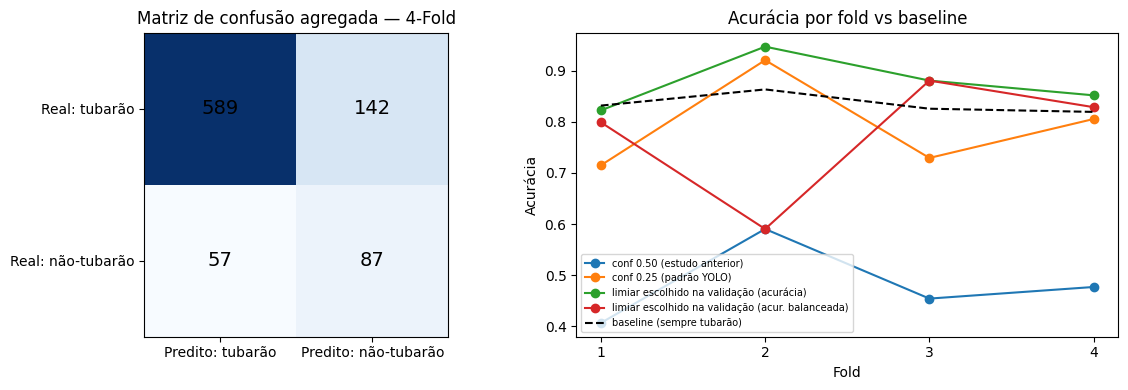

In [12]:
# Matriz de confusão agregada (as 875 imagens, cada uma testada exatamente uma vez) + IC 95% de Wilson
import matplotlib.pyplot as plt

agreg = []
for metodo, g in res.groupby("metodo", sort=False):
    TP, FP, FN, TN = (int(g[c].sum()) for c in ["TP", "FP", "FN", "TN"])
    N = TP + FP + FN + TN
    lo, hi = wilson(TP + TN, N)
    agreg.append({"Método": metodo, "TP": TP, "FP": FP, "FN": FN, "TN": TN,
                  "Acurácia agregada": f"{(TP+TN)/N:.2%}", "IC 95% (Wilson)": f"[{lo:.1%}, {hi:.1%}]",
                  "Recall agregado": f"{TP/(TP+FN):.2%}", "Especificidade agregada": f"{TN/(TN+FP):.2%}",
                  "Baseline": f"{(TP+FN)/N:.2%}"})
agreg = pd.DataFrame(agreg); display(agreg)
agreg.to_csv(SAIDA/"agregado_4folds.csv", index=False)

metodo_plot = "limiar escolhido na validação (acur. balanceada)"
g = res[res.metodo == metodo_plot]
cm = np.array([[g.TP.sum(), g.FN.sum()], [g.FP.sum(), g.TN.sum()]])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm): ax[0].text(j, i, int(v), ha="center", va="center", fontsize=14)
ax[0].set_xticks([0, 1], ["Predito: tubarão", "Predito: não-tubarão"]); ax[0].set_yticks([0, 1], ["Real: tubarão", "Real: não-tubarão"])
ax[0].set_title("Matriz de confusão agregada — 4-Fold")

for metodo, gg in res.groupby("metodo", sort=False):
    ax[1].plot(gg.fold + 1, gg.acuracia, marker="o", label=metodo)
ax[1].plot(g.fold + 1, g.baseline, "k--", label="baseline (sempre tubarão)")
ax[1].set_xticks(range(1, N_FOLDS + 1)); ax[1].set_xlabel("Fold"); ax[1].set_ylabel("Acurácia")
ax[1].set_title("Acurácia por fold vs baseline"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(SAIDA/"matriz_e_acuracia_por_fold.png", dpi=150); plt.show()

In [13]:
# Falsos negativos (tubarões não detectados) com o método de limiar escolhido na validação
fn_lista = []
for k in range(N_FOLDS):
    thr = float(res[(res.fold == k) & (res.metodo == metodo_plot)].limiar.iloc[0])
    p = pd.DataFrame([x for x in preds_teste if x["fold"] == k])
    fn_lista.append(p[(p.y == 1) & (p.score < thr)].assign(limiar=thr))
fn_df = pd.concat(fn_lista)
fn_df.to_csv(SAIDA/"falsos_negativos.csv", index=False)
print(f"{len(fn_df)} falsos negativos. Lista salva em falsos_negativos.csv (útil para a análise de erros do TCC).")
fn_df.head(15)

142 falsos negativos. Lista salva em falsos_negativos.csv (útil para a análise de erros do TCC).


,fold,nome,y,score,limiar
10,0,00145.jpg,1,0.044473,0.125
17,0,00169.png,1,0.088852,0.125
21,0,00183.webp,1,0.064229,0.125
31,0,0022.jpg,1,0.108833,0.125
35,0,00235.jpg,1,0.121141,0.125
50,0,00290.jpg,1,0.097704,0.125
59,0,0057.jpg,1,0.098313,0.125
60,0,00591.png,1,0.071767,0.125
68,0,00618.png,1,0.117211,0.125
70,0,00628.png,1,0.082868,0.125


## Como reportar no TCC

- **Metodologia:** 4-Fold estratificado e agrupado por similaridade visual (hash perceptual); limiar de confiança escolhido em validação interna (~1/6 do treino) e aplicado ao fold de teste; sementes fixas (`seed = 42`).
- **Resultado principal:** a linha "limiar escolhido na validação" da tabela, acompanhada do **baseline "sempre tubarão"** e de **Recall**, **especificidade** e **acurácia balanceada**. Reportar o baseline junto evita que a acurácia seja questionada em uma base com ~83,5% de imagens positivas.
- **Comparação com o estudo anterior:** a linha `conf 0.50` reproduz o critério anterior neste novo conjunto e fold.
- **Limitações a mencionar:** poucas imagens negativas (144; cerca de 36 por fold de teste), o que dá margem de erro grande à especificidade; um único modelo (YOLO11s); e imagens retiradas do conjunto (6 ambíguas e 3 excluídas).

In [17]:
print("=== FOLDS ===")
print(resumo.to_string())
print("\n=== TABELA FINAL (média ± desvio entre os 4 folds) ===")
print(tabela.to_string(index=False))
print("\n=== AGREGADO (875 imagens, cada uma testada uma vez) ===")
print(agreg.to_string(index=False))
print("\n=== BOX-LEVEL ===")
print(bx.to_string(index=False))
print("\n=== LIMIARES ESCOLHIDOS POR FOLD ===")
print(res[res.metodo.str.contains("validação")][["fold", "metodo", "limiar", "acuracia", "recall", "especificidade"]].round(3).to_string(index=False))
print("\n=== GRUPOS ===")
print("Maiores grupos:", tam_grupos.head(10).tolist())
print("Falsos negativos:", len(fn_df))

=== FOLDS ===
      imagens  com_tubarao  grupos  sem_tubarao baseline_sempre_tubarao
fold                                                                   
0         214          178     141           36                   83.2%
1         227          196     142           31                   86.3%
2         218          180     143           38                   82.6%
3         216          177     144           39                   81.9%

=== TABELA FINAL (média ± desvio entre os 4 folds) ===
                               Método de decisão        Acurácia       Precisão          Recall  Especificidade Acur. balanceada              F1 Baseline (sempre tubarão) Acurácia − baseline
                     conf 0.50 (estudo anterior)  48.20% ± 7.79% 96.90% ± 0.38% 39.04% ± 10.51%  93.59% ± 2.19%   66.32% ± 4.26% 55.08% ± 10.24%                    83.51%         -35.31 p.p.
                         conf 0.25 (padrão YOLO)  79.26% ± 9.42% 94.23% ± 2.10% 79.85% ± 11.10%  75.97% ± 6.85%   77